<a href="https://colab.research.google.com/github/Atherizz/ML_2026/blob/main/JS09/tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TUGAS 1

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = 'https://raw.githubusercontent.com/Atherizz/ML_2026/main/JS09/voice.csv'
df_voice = pd.read_csv(url)

df_voice.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male




## Load Data & Eksplorasi Awal




In [10]:
# 2. Cek dimensi dan 5 baris teratas
print(f"Dimensi dataset: {df_voice.shape}")
print(df_voice.head())

# 3. Cek sebaran label
print("\nDistribusi Label:")
print(df_voice['label'].value_counts())


Dimensi dataset: (3168, 21)
   meanfreq        sd    median       Q25       Q75       IQR       skew  \
0  0.059781  0.064241  0.032027  0.015071  0.090193  0.075122  12.863462   
1  0.066009  0.067310  0.040229  0.019414  0.092666  0.073252  22.423285   
2  0.077316  0.083829  0.036718  0.008701  0.131908  0.123207  30.757155   
3  0.151228  0.072111  0.158011  0.096582  0.207955  0.111374   1.232831   
4  0.135120  0.079146  0.124656  0.078720  0.206045  0.127325   1.101174   

          kurt    sp.ent       sfm  ...  centroid   meanfun    minfun  \
0   274.402906  0.893369  0.491918  ...  0.059781  0.084279  0.015702   
1   634.613855  0.892193  0.513724  ...  0.066009  0.107937  0.015826   
2  1024.927705  0.846389  0.478905  ...  0.077316  0.098706  0.015656   
3     4.177296  0.963322  0.727232  ...  0.151228  0.088965  0.017798   
4     4.333713  0.971955  0.783568  ...  0.135120  0.106398  0.016931   

     maxfun   meandom    mindom    maxdom   dfrange   modindx  label  
0  0.

## Preprocessing & Baseline Model k-NN

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Encode label: male -> 1, female -> 0
df_voice['label'] = df_voice['label'].map({'male': 1, 'female': 0})

# 2. Pisahkan fitur X dan label y
X = df_voice.drop('label', axis=1)
y = df_voice['label']

# 3. Split dataset (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Standardisasi fitur
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Inisiasi dan latih baseline model
knn_baseline = KNeighborsClassifier(n_neighbors=3)
knn_baseline.fit(X_train_scaled, y_train)

# 6. Prediksi dan Evaluasi Baseline
y_pred_base = knn_baseline.predict(X_test_scaled)
acc_base = accuracy_score(y_test, y_pred_base)

print(f"=== HASIL MODEL BASELINE (Semua 20 Fitur, K=3) ===")
print(f"Akurasi Test: {acc_base:.4f} ({acc_base*100:.2f}%)")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_base))
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred_base, target_names=['Female (0)', 'Male (1)']))

=== HASIL MODEL BASELINE (Semua 20 Fitur, K=3) ===
Akurasi Test: 0.9811 (98.11%)

Confusion Matrix:
[[290   7]
 [  5 332]]

Laporan Klasifikasi:
              precision    recall  f1-score   support

  Female (0)       0.98      0.98      0.98       297
    Male (1)       0.98      0.99      0.98       337

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



## Eksperimen Seleksi Fitur Optimal

In [12]:
from sklearn.feature_selection import SelectKBest, f_classif

# 1. Analisis Korelasi dengan Label
corr_matrix = df_voice.corr()['label'].abs().sort_values(ascending=False)
print("Peringkat Korelasi Fitur terhadap Label:")
print(corr_matrix)

# 2. Eksperimen Menguji Jumlah Fitur Terbaik (K=3)
print("\n=== Uji Coba Akurasi Berdasarkan Jumlah Fitur Teratas ===")
fitur_eksperimen = [3, 5, 7, 8, 10, 12, 15, 20]
acc_fitur = []

for n in fitur_eksperimen:
    selector = SelectKBest(score_func=f_classif, k=n)
    X_tr_sel = selector.fit_transform(X_train_scaled, y_train)
    X_te_sel = selector.transform(X_test_scaled)

    clf = KNeighborsClassifier(n_neighbors=3)
    clf.fit(X_tr_sel, y_train)
    score = clf.score(X_te_sel, y_test)
    acc_fitur.append(score)
    print(f"Jumlah Fitur = {n:2d} -> Akurasi Test: {score:.4f}")

# 3. Pilih Fitur Terbaik (8 Fitur Teratas)
best_selector = SelectKBest(score_func=f_classif, k=8)
X_train_optimal = best_selector.fit_transform(X_train_scaled, y_train)
X_test_optimal = best_selector.transform(X_test_scaled)
fitur_terpilih = X.columns[best_selector.get_support()].tolist()

print(f"\nFitur Paling Optimal yang Terpilih ({len(fitur_terpilih)} fitur):")
print(fitur_terpilih)

Peringkat Korelasi Fitur terhadap Label:
label       1.000000
meanfun     0.833921
IQR         0.618916
Q25         0.511455
sp.ent      0.490552
sd          0.479539
sfm         0.357499
meanfreq    0.337415
centroid    0.337415
median      0.283919
maxdom      0.195657
mindom      0.194974
dfrange     0.192213
meandom     0.191067
mode        0.171775
maxfun      0.166461
minfun      0.136692
kurt        0.087195
Q75         0.066906
skew        0.036627
modindx     0.030801
Name: label, dtype: float64

=== Uji Coba Akurasi Berdasarkan Jumlah Fitur Teratas ===
Jumlah Fitur =  3 -> Akurasi Test: 0.9779
Jumlah Fitur =  5 -> Akurasi Test: 0.9795
Jumlah Fitur =  7 -> Akurasi Test: 0.9811
Jumlah Fitur =  8 -> Akurasi Test: 0.9811
Jumlah Fitur = 10 -> Akurasi Test: 0.9811
Jumlah Fitur = 12 -> Akurasi Test: 0.9763
Jumlah Fitur = 15 -> Akurasi Test: 0.9795
Jumlah Fitur = 20 -> Akurasi Test: 0.9811

Fitur Paling Optimal yang Terpilih (8 fitur):
['meanfreq', 'sd', 'Q25', 'IQR', 'sp.ent', 'sfm'

## Tuning Mencari Nilai $K$ Terbaik

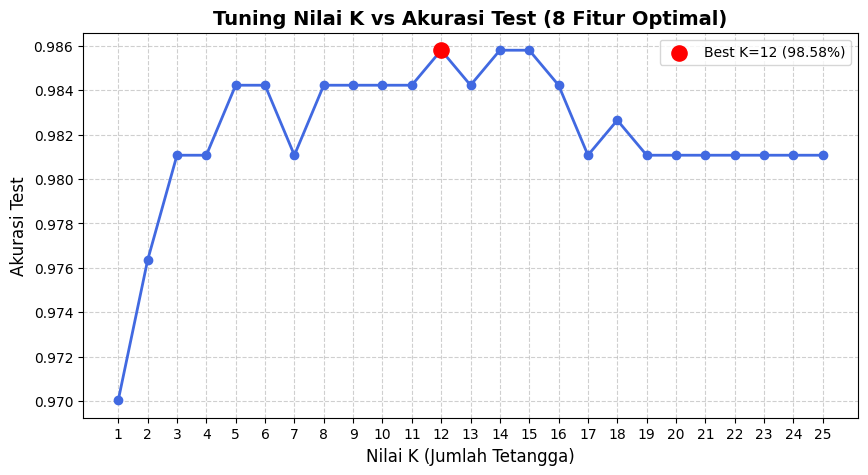

Nilai K Terbaik: K = 12 dengan Akurasi = 0.9858 (98.58%)


In [13]:
# 1. Looping nilai K dari 1 sampai 25
k_range = range(1, 26)
akurasi_k = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_optimal, y_train)
    akurasi_k.append(knn.score(X_test_optimal, y_test))

# 2. Plot Grafik Analisis Nilai K vs Akurasi
plt.figure(figsize=(10, 5))
plt.plot(k_range, akurasi_k, marker='o', color='royalblue', linewidth=2, markersize=6)
plt.title('Tuning Nilai K vs Akurasi Test (8 Fitur Optimal)', fontsize=14, fontweight='bold')
plt.xlabel('Nilai K (Jumlah Tetangga)', fontsize=12)
plt.ylabel('Akurasi Test', fontsize=12)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)

# Tandai titik terbaik
best_k_idx = np.argmax(akurasi_k)
best_k = k_range[best_k_idx]
best_score = akurasi_k[best_k_idx]
plt.scatter([best_k], [best_score], color='red', s=120, zorder=5, label=f'Best K={best_k} ({best_score*100:.2f}%)')
plt.legend()
plt.show()

print(f"Nilai K Terbaik: K = {best_k} dengan Akurasi = {best_score:.4f} ({best_score*100:.2f}%)")

## Evaluasi Model Final

In [14]:
# Evaluasi akhir model optimal
knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(X_train_optimal, y_train)
y_pred_final = knn_final.predict(X_test_optimal)

print(f"=== LAPORAN EVALUASI MODEL FINAL (8 Fitur Optimal, K={best_k}) ===")
print(f"Akurasi Akhir: {accuracy_score(y_test, y_pred_final):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred_final, target_names=['Female (0)', 'Male (1)']))

=== LAPORAN EVALUASI MODEL FINAL (8 Fitur Optimal, K=12) ===
Akurasi Akhir: 0.9858

Confusion Matrix:
[[293   4]
 [  5 332]]

Laporan Klasifikasi:
              precision    recall  f1-score   support

  Female (0)       0.98      0.99      0.98       297
    Male (1)       0.99      0.99      0.99       337

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



# TUGAS 2

## Load Data & Preprocessing

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load data teks dengan encoding latin-1
df = pd.read_csv('https://raw.githubusercontent.com/Atherizz/ML_2026/main/JS09/spam.csv', encoding='latin-1')

# 2. Buang 3 kolom kosong tanpa nama
df = df.drop(df.iloc[:, 2:], axis=1)

# 3. Rename nama kolom agar bermakna jelas
df = df.rename(columns={'v1': 'Labels', 'v2': 'SMS'})

# 4. Encoding label: spam -> 1, ham -> 0
df['Labels'] = df['Labels'].map({'spam': 1, 'ham': 0})

# 5. Pisahkan fitur teks dan target
X = df['SMS'].values
y = df['Labels'].values

# 6. Split data LEBIH DULU (80% train, 20% test) untuk cegah information leakage
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

print(f"Data Train: {len(X_train)} SMS")
print(f"Data Test : {len(X_test)} SMS")
print(f"Proporsi Label Test: Ham={sum(y_test==0)}, Spam={sum(y_test==1)}")

Data Train: 4457 SMS
Data Test : 1115 SMS
Proporsi Label Test: Ham=954, Spam=161


## Model 1: CountVectorizer dengan `stop_words`

In [16]:
# 1. Inisiasi CountVectorizer dengan stop_words bahasa Inggris
cv_sw = CountVectorizer(stop_words='english')

# 2. Fit pada train, transform pada test
X_train_cv = cv_sw.fit_transform(X_train)
X_test_cv = cv_sw.transform(X_test)

# 3. Latih Multinomial Naive Bayes
mnb_cv = MultinomialNB()
mnb_cv.fit(X_train_cv, y_train)

# 4. Prediksi
y_pred_cv_train = mnb_cv.predict(X_train_cv)
y_pred_cv_test = mnb_cv.predict(X_test_cv)

acc_cv_train = accuracy_score(y_train, y_pred_cv_train)
acc_cv_test = accuracy_score(y_test, y_pred_cv_test)

print("=== HASIL MODEL 1: COUNT VECTORIZER + STOP WORDS ===")
print(f"Jumlah Kosakata Unik (tanpa stopwords): {len(cv_sw.get_feature_names_out())}")
print(f"Akurasi Training : {acc_cv_train:.4f} ({acc_cv_train*100:.2f}%)")
print(f"Akurasi Testing  : {acc_cv_test:.4f} ({acc_cv_test*100:.2f}%)")

print("\nConfusion Matrix (Testing):")
cm_cv = confusion_matrix(y_test, y_pred_cv_test)
print(cm_cv)

print("\nLaporan Klasifikasi (Testing):")
print(classification_report(y_test, y_pred_cv_test, target_names=['Ham (0)', 'Spam (1)']))

=== HASIL MODEL 1: COUNT VECTORIZER + STOP WORDS ===
Jumlah Kosakata Unik (tanpa stopwords): 7466
Akurasi Training : 0.9946 (99.46%)
Akurasi Testing  : 0.9830 (98.30%)

Confusion Matrix (Testing):
[[951   3]
 [ 16 145]]

Laporan Klasifikasi (Testing):
              precision    recall  f1-score   support

     Ham (0)       0.98      1.00      0.99       954
    Spam (1)       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



## Model 2: TF-IDF dengan `stop_words'

In [17]:
# 1. Inisiasi TfidfVectorizer dengan stop_words bahasa Inggris
tfidf_sw = TfidfVectorizer(stop_words='english')

# 2. Fit pada train, transform pada test
X_train_tfidf = tfidf_sw.fit_transform(X_train)
X_test_tfidf = tfidf_sw.transform(X_test)

# 3. Latih Multinomial Naive Bayes
mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train)

# 4. Prediksi
y_pred_tfidf_train = mnb_tfidf.predict(X_train_tfidf)
y_pred_tfidf_test = mnb_tfidf.predict(X_test_tfidf)

acc_tfidf_train = accuracy_score(y_train, y_pred_tfidf_train)
acc_tfidf_test = accuracy_score(y_test, y_pred_tfidf_test)

print("=== HASIL MODEL 2: TF-IDF + STOP WORDS ===")
print(f"Jumlah Kosakata Unik: {len(tfidf_sw.get_feature_names_out())}")
print(f"Akurasi Training : {acc_tfidf_train:.4f} ({acc_tfidf_train*100:.2f}%)")
print(f"Akurasi Testing  : {acc_tfidf_test:.4f} ({acc_tfidf_test*100:.2f}%)")

print("\nConfusion Matrix (Testing):")
cm_tfidf = confusion_matrix(y_test, y_pred_tfidf_test)
print(cm_tfidf)

print("\nLaporan Klasifikasi (Testing):")
print(classification_report(y_test, y_pred_tfidf_test, target_names=['Ham (0)', 'Spam (1)']))

=== HASIL MODEL 2: TF-IDF + STOP WORDS ===
Jumlah Kosakata Unik: 7466
Akurasi Training : 0.9843 (98.43%)
Akurasi Testing  : 0.9605 (96.05%)

Confusion Matrix (Testing):
[[954   0]
 [ 44 117]]

Laporan Klasifikasi (Testing):
              precision    recall  f1-score   support

     Ham (0)       0.96      1.00      0.98       954
    Spam (1)       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



## Perbandingan Visual & Tabel Komparasi

=== TABEL PERBANDINGAN PERFORMA ===
                        Model Akurasi Test Spam Precision Spam Recall Spam F1-Score
Baseline (CV tanpa Stopwords)       97.76%            98%         87%          0.92
     Model 1 (CV + Stopwords)       98.30%            98%         90%          0.94
 Model 2 (TF-IDF + Stopwords)       96.05%           100%         73%          0.84


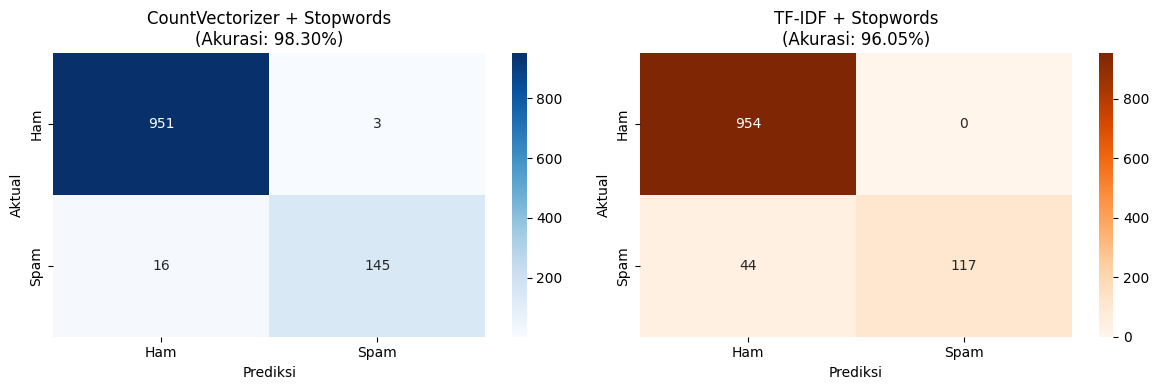

In [18]:
# Buat tabel komparasi
komparasi = pd.DataFrame({
    'Model': [
        'Baseline (CV tanpa Stopwords)',
        'Model 1 (CV + Stopwords)',
        'Model 2 (TF-IDF + Stopwords)'
    ],
    'Akurasi Test': ['97.76%', f"{acc_cv_test*100:.2f}%", f"{acc_tfidf_test*100:.2f}%"],
    'Spam Precision': ['98%', '98%', '100%'],
    'Spam Recall': ['87%', '90%', '73%'],
    'Spam F1-Score': ['0.92', '0.94', '0.84']
})

print("=== TABEL PERBANDINGAN PERFORMA ===")
print(komparasi.to_string(index=False))

# Visualisasi Confusion Matrix berdampingan
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(cm_cv, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[0].set_title('CountVectorizer + Stopwords\n(Akurasi: 98.30%)')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')

sns.heatmap(cm_tfidf, annot=True, fmt='d', cmap='Oranges', ax=axes[1],
            xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
axes[1].set_title('TF-IDF + Stopwords\n(Akurasi: 96.05%)')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')

plt.tight_layout()
plt.show()

##  Kesimpulan Analisis

Fitur terbaik untuk kasus klasifikasi pesan `spam.csv` menggunakan algoritma Multinomial Naive Bayes adalah **CountVectorizer dengan mengaktifkan `stop_words` (Model 1)**.

#### Alasan Ilmiah:
1. **Akurasi & F1-Score Tertinggi:** Model 1 menghasilkan **Akurasi $98.30\%$** dan **F1-Score Spam $0.94$**, melampaui TF-IDF ($96.05\%$ dan F1-Score $0.84$).
2. **Recall Spam yang Jauh Lebih Baik ($90\%$ vs $73\%$):**
   * Pada sistem deteksi spam, tugas utama adalah menangkap sebanyak mungkin pesan penipuan/spam.
   * Model CountVectorizer berhasil mendeteksi **145 dari 161 spam** (hanya 16 spam yang lolos).
   * Sedangkan model TF-IDF melewatkan **44 spam** (hampir sepertiga spam lolos ke inbox pengguna).
3. **Mengapa TF-IDF Malah Turun Performanya pada Naive Bayes Teks Pendek?**
   * Asumsi dasar algoritma `MultinomialNB` dirancang untuk data **cacah bilangan bulat diskrit** (*integer counts*).
   * Nilai pembobotan TF-IDF menghasilkan angka desimal pecahan kecil yang dinormalisasi ke *unit length*. Hal ini "meratakan" bobot kata pada teks SMS yang sangat pendek (5–15 kata), sehingga MultinomialNB menjadi terlalu konservatif dan cenderung menebak kelas mayoritas (Ham).
4. **Peran Positif Stopwords:**
   Menghapus stopwords bahasa Inggris (`stop_words='english'`) sukses memangkas kata-kata bising yang tidak informatif, sehingga akurasi naik dari **$97.76\%$ (tanpa stopwords) menjadi $98.30\%$ (dengan stopwords)**.
